# Kerr quasinormal modes followed in spin

We follow gravitational quasinormal modes ($s=-2$, $m=2$) of a Kerr black hole from Schwarzschild, $a=0$, to $a/M=0.7$,
for overtones up to $n=500$. Two families start from the two lowest Schwarzschild multipoles: the **prolate** side starts
at $\ell=2$ ($n=20,50,100,\dots,500$) and the **oblate** side at $\ell=3$ ($n=20,50,\dots,350$). At every accepted spin the
code saves the frequency $\omega$, the angular eigenvalue $A$ and the angular eigenvector.

This notebook reads those saved modes from `results/` and compares them with the high-damping predictions of the
literature: the real frequency, the spacing of the damping and the angular eigenvalue, on both sides. It ends with a
cell that computes new modes.

**Run All only reads and draws (a few seconds).** Nothing is solved unless you set `COMPUTE = True` in the last cell.

Conventions: $M=1$, dependence $e^{-i\omega t+im\phi}$, $\chi=a/M$, $c=a\omega$ (so $c=\chi\,M\omega$),
$\omega=\omega_{\rm R}+i\,\omega_{\rm I}$ with $\omega_{\rm I}<0$.

## What is solved

At fixed spin the Teukolsky equation separates into an angular and a radial equation that share $\omega$ and $A$.
A QNM has an angular function regular at both poles, a wave falling into the horizon and no wave coming in from
infinity, so at fixed $\chi$ it is a zero of
$$F(\omega)=R\bigl(\omega,A(c)\bigr),$$
where $R$ is a radial residual.

- $A(c)$ and $S(\theta)$ come from a matrix eigenproblem on spin-weighted spherical harmonics
  ([`solver/angular.py`](solver/angular.py)). This basis already enforces regularity at both poles.
- $R$ is Leaver's continued fraction with a Nollert tail ([`solver/radial.py`](solver/radial.py)). Near and past
  $\mathrm{Re}\,\omega=0$ the code uses instead a confluent Heun residual integrated along a tilted ray
  ([`solver/heun.py`](solver/heun.py)).
- A complex secant finds the root at fixed $\chi$ ([`solver/solve.py`](solver/solve.py)), and the walk in spin keeps
  a root only if it continues the previous point: $\omega$ close to the prediction and sufficient overlap with the preceding angular eigenvector
  ([`solver/continuation.py`](solver/continuation.py)).

On the prolate side the overtones from $n=100$ on cross $\mathrm{Re}\,\omega=0$ early in the walk (near $\chi\simeq20/n$).
The saved $n=20$ and $50$ stay at $\mathrm{Re}\,\omega>0$, close to $m\Omega_H$ at $\chi=0.7$, so the prolate comparisons
below use $n\ge100$.

The Heun calculation specifies a continuation path through this region. Agreement at the switch does not independently identify the physical Green-function sheet.

## High-damping predictions

| | prolate | oblate |
|---|---|---|
| $M\omega_{\rm R}\to$ | $C_{\rm KH}=-m\,\delta_m/\delta_0$ | $m\,M\Omega_H$ |
| growth of $-M\omega_{\rm I}$ per overtone | $S_{\rm KH}=2\pi/\delta_0$ | $M\kappa_H$ |
| $A\simeq$ | $ic+\frac{37}{4}+\frac{93/16+16i}{ic}$ | $-c^2-2c+3$ |

- Prolate frequencies: Keshet and Hod, Phys. Rev. D 76, 061501 (2007); $\delta_0$ and $\delta_m$ are their action integrals.
- Oblate frequencies: Keshet and Ben-Meir, arXiv:1207.2460, with $r_+=1+\sqrt{1-\chi^2}$, $M\Omega_H=\chi/(2r_+)$,
  $M\kappa_H=\sqrt{1-\chi^2}/(2r_+)$.
- Prolate $A$: Vickers and Cook, arXiv:2208.06259. Oblate $A$: Berti, Cardoso and Casals, Phys. Rev. D 73, 024013 (2006).

They are all computed in [`solver/asymptotics.py`](solver/asymptotics.py) and drawn as dashed lines. Nothing is fitted. The angular comparisons retain terms through $1/(ic)$ for prolate and through $c^0$ for oblate.

In [1]:
from pathlib import Path
import sys
import os

# Use one BLAS thread for reproducible comparisons.
for name in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ[name] = "1"

sys.dont_write_bytecode = True                     # keep solver/ free of __pycache__
WORK = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "solver" / "seeds.py").exists())
sys.path.insert(0, str(WORK / "solver"))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
import results
from asymptotics import horizon, keshet_hod, oblate_A, prolate_A

PROLATE_FOLDER = WORK / "results" / "prolate"      # the saved modes; point these to your own runs to draw them
OBLATE_FOLDER = WORK / "results" / "oblate"
CHI_END = 0.7

prolate = results.load_modes(PROLATE_FOLDER, 2)
oblate = results.load_modes(OBLATE_FOLDER, 3)
deep = [mode for mode in prolate if mode.n >= 100]  # prolate modes past Re(omega) = 0

plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.labelsize": 12, "axes.titlesize": 12.5,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "legend.frameon": False, "mathtext.fontset": "stix"})


def shades(modes, side):
    # one color per mode, light for low n and dark for high n: blue prolate, orange oblate
    cmap = "Blues" if side == "prolate" else "Oranges"
    return plt.colormaps[cmap](np.linspace(0.35, 0.95, len(modes)))


# the predictions on a grid of spins
chi = np.linspace(0.005, CHI_END, 140)
C_KH, S_KH = np.array([keshet_hod(x) for x in chi]).T
r_plus, Omega_H, kappa_H = horizon(chi)

print("prolate n:", [mode.n for mode in prolate])
print("oblate n: ", [mode.n for mode in oblate])

prolate n: [20, 50, 100, 150, 200, 250, 300, 350, 400, 450, 500]
oblate n:  [20, 50, 100, 150, 200, 250, 300, 350]


## The saved modes

The last accepted state of every walk. `states` counts the accepted spins; `Heun` counts those solved with the
Heun residual.

In [2]:
def endpoint_table(modes, side):
    rows = [r"| " + side + r" $n$ | $a/M$ | $M\omega_{\rm R}$ | $-M\omega_{\rm I}$ | ${\rm Re}\,A$ | ${\rm Im}\,A$ | states | Heun |",
            "|---" * 8 + "|"]
    for mode in modes:
        w, A = mode.omega[-1], mode.A[-1]
        heun = (mode.method == "heun").sum()
        rows.append(f"| {mode.n} | {mode.chi[-1]:.2f} | {w.real:.10f} | {-w.imag:.10f} | {A.real:.8f} | {A.imag:.8f} "
                    f"| {len(mode.chi)} | {heun} |")
    return "\n".join(rows)


display(Markdown(endpoint_table(prolate, "prolate")))
display(Markdown(endpoint_table(oblate, "oblate")))

| prolate $n$ | $a/M$ | $M\omega_{\rm R}$ | $-M\omega_{\rm I}$ | ${\rm Re}\,A$ | ${\rm Im}\,A$ | states | Heun |
|---|---|---|---|---|---|---|---|
| 20 | 0.70 | 0.4066177135 | 3.7538071621 | 9.10788056 | 7.00898464 | 143 | 0 |
| 50 | 0.70 | 0.4084503453 | 9.9991335894 | 51.33953571 | 18.17484679 | 156 | 0 |
| 100 | 0.70 | -0.1187015109 | 24.0737344243 | 26.27556161 | 0.94428066 | 148 | 101 |
| 150 | 0.70 | -0.1177553792 | 37.0933987028 | 35.37039495 | 0.57288186 | 148 | 116 |
| 200 | 0.70 | -0.1171597654 | 50.1150985612 | 44.45962789 | 0.39699870 | 152 | 125 |
| 250 | 0.70 | -0.1167737770 | 62.8822240334 | 53.37677622 | 0.29681602 | 151 | 128 |
| 300 | 0.70 | -0.1165016802 | 75.6497110657 | 62.29899600 | 0.23122503 | 151 | 131 |
| 350 | 0.70 | -0.1163003772 | 88.4174009716 | 71.22481147 | 0.18499788 | 154 | 133 |
| 400 | 0.70 | -0.1161457187 | 101.1852158970 | 80.15316441 | 0.15068128 | 153 | 133 |
| 450 | 0.70 | -0.1160233017 | 113.9531132448 | 89.08334667 | 0.12420538 | 154 | 135 |
| 500 | 0.70 | -0.1159240553 | 126.7210677716 | 98.01488145 | 0.10316232 | 154 | 136 |

| oblate $n$ | $a/M$ | $M\omega_{\rm R}$ | $-M\omega_{\rm I}$ | ${\rm Re}\,A$ | ${\rm Im}\,A$ | states | Heun |
|---|---|---|---|---|---|---|---|
| 20 | 0.70 | 0.4223362141 | 4.0160043110 | 11.71567504 | 4.31408313 | 143 | 0 |
| 50 | 0.70 | 0.4079828747 | 10.6244766774 | 57.59858648 | 19.21242287 | 159 | 0 |
| 100 | 0.70 | 0.4084432796 | 21.0393047077 | 219.26589284 | 37.95363967 | 146 | 0 |
| 150 | 0.70 | 0.4083779284 | 31.4547946907 | 487.15955939 | 56.63800015 | 148 | 0 |
| 200 | 0.70 | 0.4083431123 | 41.8701454075 | 861.35601750 | 75.40704872 | 149 | 0 |
| 250 | 0.70 | 0.4083850868 | 52.2855880675 | 1341.91236434 | 94.15073481 | 152 | 0 |
| 300 | 0.70 | 0.4083633333 | 62.7010488808 | 1928.73984846 | 112.88090637 | 152 | 0 |
| 350 | 0.70 | 0.4083625366 | 73.1164742943 | 2621.89088063 | 131.64646813 | 155 | 0 |

## 1. Real frequency

$M\omega_{\rm R}$ along the spin, against $C_{\rm KH}$ on the prolate side and $m\Omega_H$ on the oblate side.

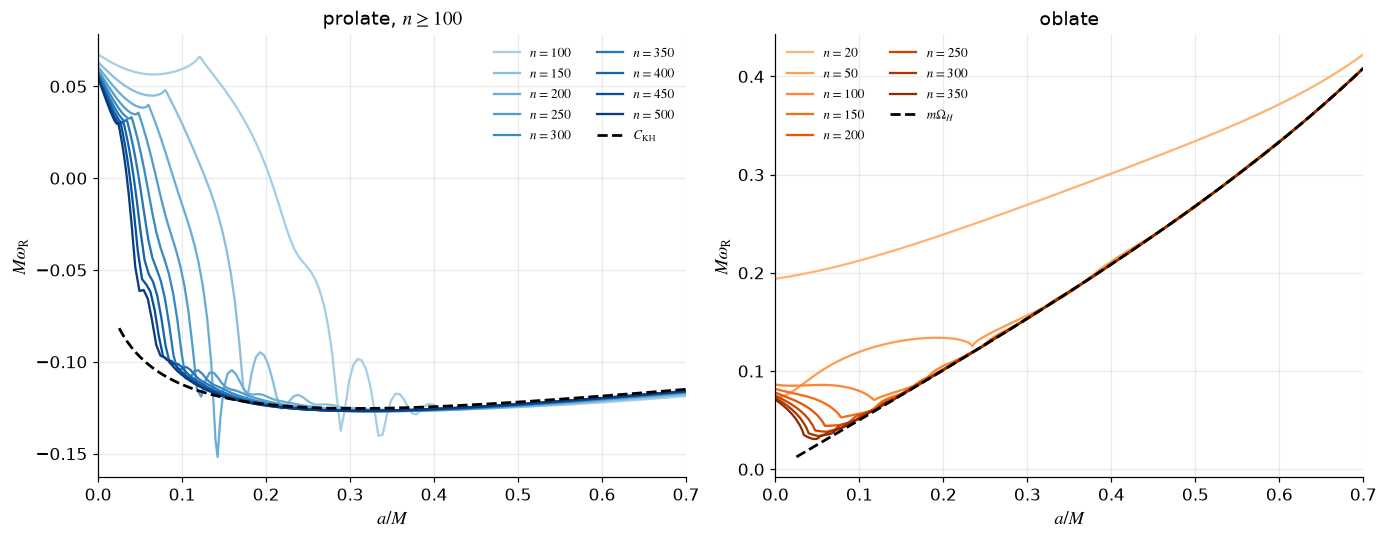

In [3]:
fig, (left, right) = plt.subplots(1, 2, figsize=(12.5, 4.8), constrained_layout=True)
for mode, color in zip(deep, shades(deep, "prolate")):
    left.plot(mode.chi, mode.omega.real, color=color, lw=1.5, label=f"$n={mode.n}$")
for mode, color in zip(oblate, shades(oblate, "oblate")):
    right.plot(mode.chi, mode.omega.real, color=color, lw=1.5, label=f"$n={mode.n}$")

shown = chi >= 0.02                                 # the limits are leading order: not drawn at the smallest spins
left.plot(chi[shown], C_KH[shown], "k--", lw=1.8, label=r"$C_{\rm KH}$")
right.plot(chi[shown], 2 * Omega_H[shown], "k--", lw=1.8, label=r"$m\Omega_H$")

left.set_title(r"prolate, $n\geq100$")
right.set_title("oblate")
for ax in (left, right):
    ax.set(xlabel=r"$a/M$", ylabel=r"$M\omega_{\rm R}$", xlim=(0, CHI_END))
    ax.legend(fontsize=8.5, ncol=2)
plt.show()

## 2. Spacing of the damping

The mean growth of $-M\omega_{\rm I}$ per overtone between two saved modes,
$-[M\omega_{\rm I}(n_2)-M\omega_{\rm I}(n_1)]/(n_2-n_1)$, along the spin (each path interpolated linearly on a common grid).
Both sides start from the Schwarzschild spacing $1/4$. On the prolate side the pairs from $200$–$250$ on follow $S_{\rm KH}$;
between $n=100$ and $200$ the spacing per label at $\chi=0.7$ is about $\tfrac{51}{50}S_{\rm KH}$.

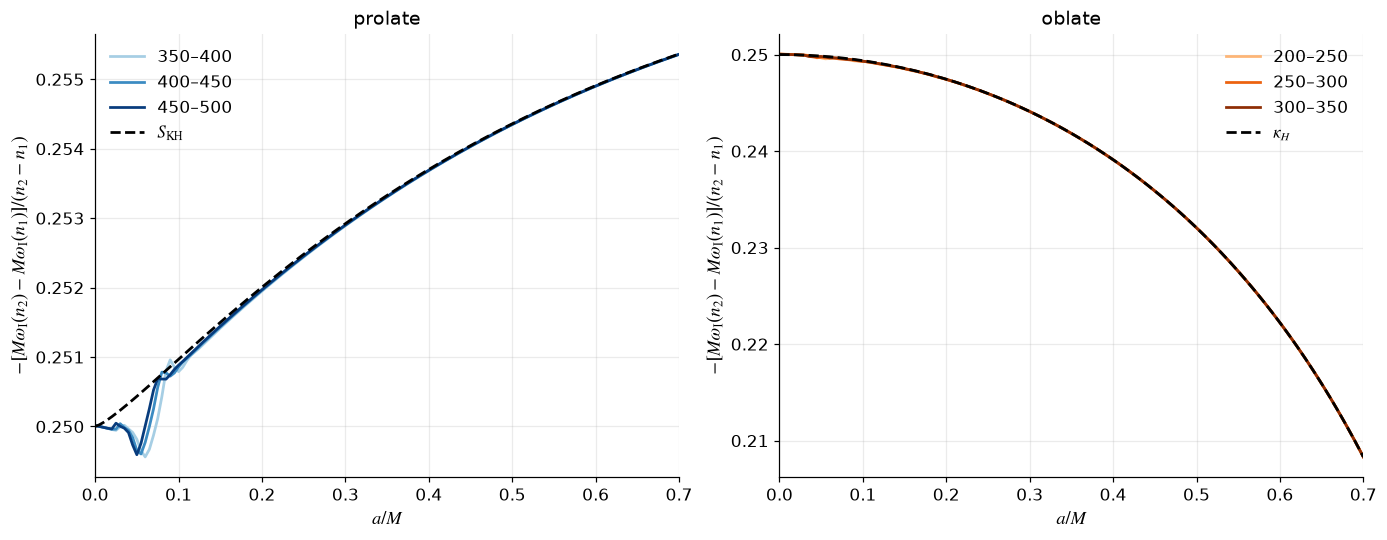

In [4]:
def spacing(mode1, mode2, grid):
    # mean growth of -M omega_I per overtone between two saved modes
    damping1 = np.interp(grid, mode1.chi, -mode1.omega.imag)
    damping2 = np.interp(grid, mode2.chi, -mode2.omega.imag)
    return (damping2 - damping1) / (mode2.n - mode1.n)


grid = np.linspace(0, CHI_END, 141)
prolate_by_n = {mode.n: mode for mode in prolate}
oblate_by_n = {mode.n: mode for mode in oblate}
prolate_pairs = [(350, 400), (400, 450), (450, 500)]
oblate_pairs = [(200, 250), (250, 300), (300, 350)]

fig, (left, right) = plt.subplots(1, 2, figsize=(12.5, 4.8), constrained_layout=True)
for (n1, n2), color in zip(prolate_pairs, shades(prolate_pairs, "prolate")):
    left.plot(grid, spacing(prolate_by_n[n1], prolate_by_n[n2], grid), color=color, lw=1.8, label=f"{n1}–{n2}")
for (n1, n2), color in zip(oblate_pairs, shades(oblate_pairs, "oblate")):
    right.plot(grid, spacing(oblate_by_n[n1], oblate_by_n[n2], grid), color=color, lw=1.8, label=f"{n1}–{n2}")

left.plot(np.r_[0, chi], np.r_[0.25, S_KH], "k--", lw=1.8, label=r"$S_{\rm KH}$")
right.plot(np.r_[0, chi], np.r_[0.25, kappa_H], "k--", lw=1.8, label=r"$\kappa_H$")

left.set_title("prolate")
right.set_title("oblate")
for ax in (left, right):
    ax.set(xlabel=r"$a/M$", ylabel=r"$-[M\omega_{\rm I}(n_2)-M\omega_{\rm I}(n_1)]/(n_2-n_1)$", xlim=(0, CHI_END))
    ax.legend()
plt.show()

## 3. Angular eigenvalue

$A$ divided by its leading term, $A/(ic)$ on the prolate side and $A/(-c^2)$ on the oblate side, against $|c|$ for $|c|\ge5$.
Dashed: the expansion of the table above divided by the same term, at each point's complex $c$. Real part first, then
imaginary part.

These are finite-damping comparisons at the complex values of $c$ supplied by the solver. The displayed truncations need not give a uniform error along the whole spin path.

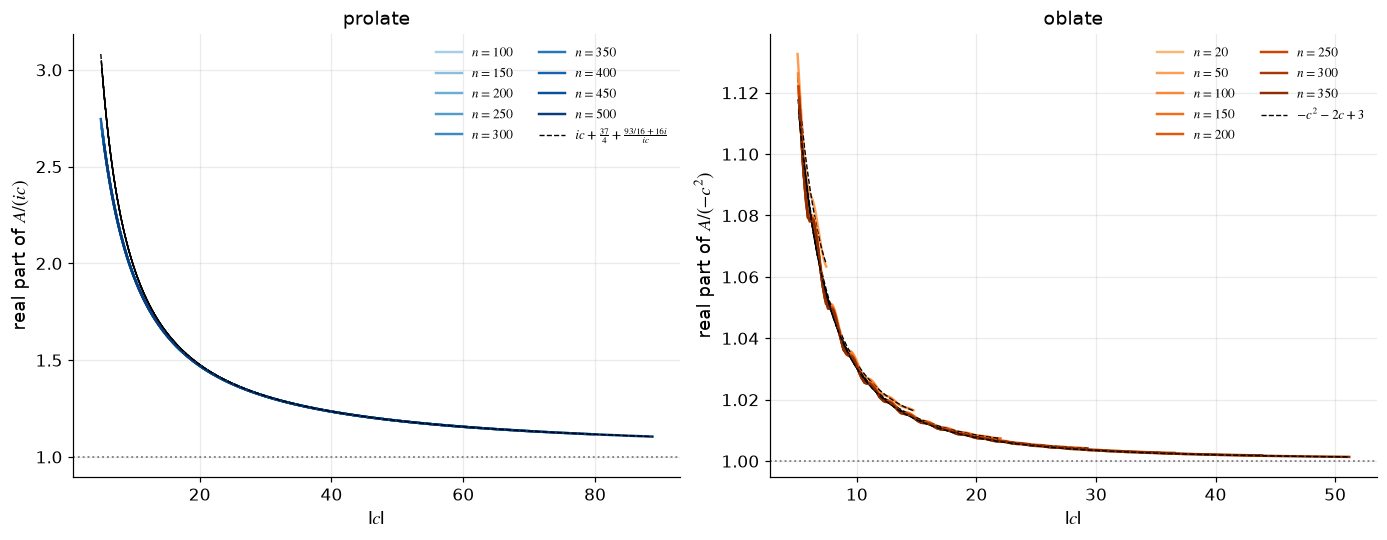

In [5]:
def angular_ratio(mode, side):
    # |c|, A over its leading term, and the expansion over the same term, for |c| >= 5
    c = mode.chi * mode.omega
    big = abs(c) >= 5
    c, A = c[big], mode.A[big]
    if side == "prolate":
        lead, expansion = 1j * c, prolate_A(c)
    else:
        lead, expansion = -c * c, oblate_A(c)
    return abs(c), A / lead, expansion / lead


def angular_figure(part):
    # part = np.real or np.imag
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), constrained_layout=True)
    for ax, side, modes in ((axes[0], "prolate", deep), (axes[1], "oblate", oblate)):
        for mode, color in zip(modes, shades(modes, side)):
            size, ratio, expansion = angular_ratio(mode, side)
            ax.plot(size, part(ratio), color=color, lw=1.6, label=f"$n={mode.n}$")
            ax.plot(size, part(expansion), "k--", lw=0.9)
        formula = r"$ic+\frac{37}{4}+\frac{93/16+16i}{ic}$" if side == "prolate" else r"$-c^2-2c+3$"
        ax.plot([], [], "k--", lw=0.9, label=formula)
        ax.axhline(1.0 if part is np.real else 0.0, color="0.5", ls=":", lw=1.2)
        name = "real part" if part is np.real else "imaginary part"
        ratio_name = r"$A/(ic)$" if side == "prolate" else r"$A/(-c^2)$"
        ax.set(title=side, xlabel=r"$|c|$", ylabel=f"{name} of {ratio_name}")
        ax.legend(fontsize=8.5, ncol=2)
    plt.show()


angular_figure(np.real)

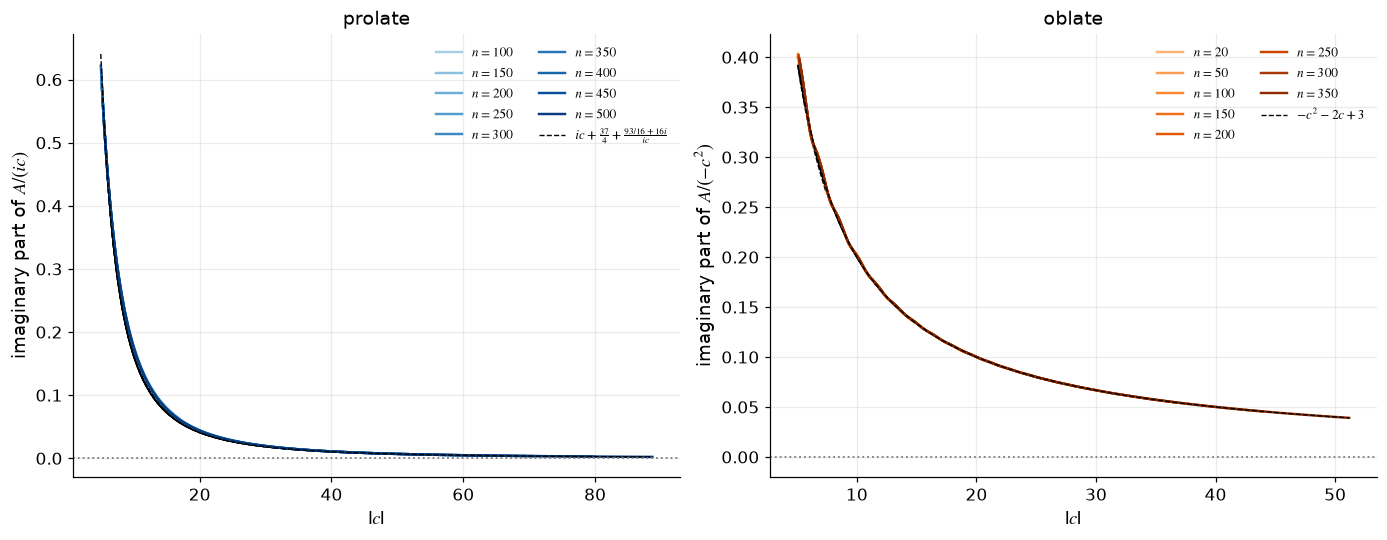

In [6]:
angular_figure(np.imag)

## The numbers at $a/M=0.7$

Each saved mode against the predictions: the distance of $M\omega_{\rm R}$ from its limit, the spacing to the next saved
overtone minus the predicted one, and the relative distance of $A$ from its expansion.

In [7]:
C_end, S_end = keshet_hod(CHI_END)
_, Omega_end, kappa_end = horizon(CHI_END)


def comparison_table(modes, side):
    limit, predicted = (C_end, S_end) if side == "prolate" else (2 * Omega_end, kappa_end)
    rows = [r"| " + side + r" $n$ | $M\omega_{\rm R}$ − limit | spacing to the next $n$ − prediction | $\lvert A-A_{\rm expansion}\rvert/\lvert A\rvert$ |",
            "|---|---|---|---|"]
    for k, mode in enumerate(modes):
        w, A = mode.omega[-1], mode.A[-1]
        c = CHI_END * w
        expansion = prolate_A(c) if side == "prolate" else oblate_A(c)
        gap = ""
        if k + 1 < len(modes):
            following = modes[k + 1]
            gap = f"{(w.imag - following.omega[-1].imag) / (following.n - mode.n) - predicted:+.1e}"
        rows.append(f"| {mode.n} | {w.real - limit:+.2e} | {gap} | {abs(A - expansion) / abs(A):.1e} |")
    return "\n".join(rows)


display(Markdown(comparison_table(deep, "prolate")))
display(Markdown(comparison_table(oblate, "oblate")))
display(Markdown(f"Predictions at $a/M=0.7$: $C_{{\\rm KH}}={C_end:.8f}$, $S_{{\\rm KH}}={S_end:.8f}$, "
                 f"$m\\Omega_H={2 * Omega_end:.8f}$, $\\kappa_H={kappa_end:.8f}$."))

| prolate $n$ | $M\omega_{\rm R}$ − limit | spacing to the next $n$ − prediction | $\lvert A-A_{\rm expansion}\rvert/\lvert A\rvert$ |
|---|---|---|---|
| 100 | -3.72e-03 | +5.0e-03 | 7.0e-03 |
| 150 | -2.77e-03 | +5.1e-03 | 2.2e-03 |
| 200 | -2.18e-03 | -2.1e-05 | 9.5e-04 |
| 250 | -1.79e-03 | -1.4e-05 | 5.0e-04 |
| 300 | -1.52e-03 | -9.7e-06 | 2.9e-04 |
| 350 | -1.32e-03 | -7.2e-06 | 1.9e-04 |
| 400 | -1.16e-03 | -5.6e-06 | 1.3e-04 |
| 450 | -1.04e-03 | -4.4e-06 | 9.0e-05 |
| 500 | -9.42e-04 |  | 6.6e-05 |

| oblate $n$ | $M\omega_{\rm R}$ − limit | spacing to the next $n$ − prediction | $\lvert A-A_{\rm expansion}\rvert/\lvert A\rvert$ |
|---|---|---|---|
| 20 | +1.40e-02 | +1.2e-02 | 2.7e-01 |
| 50 | -3.84e-04 | -1.2e-05 | 1.8e-03 |
| 100 | +7.59e-05 | +7.8e-07 | 3.6e-04 |
| 150 | +1.06e-05 | -2.0e-06 | 2.8e-05 |
| 200 | -2.43e-05 | -1.7e-07 | 4.2e-05 |
| 250 | +1.77e-05 | +1.9e-07 | 2.1e-05 |
| 300 | -4.03e-06 | -5.2e-07 | 3.9e-06 |
| 350 | -4.83e-06 |  | 8.8e-06 |

Predictions at $a/M=0.7$: $C_{\rm KH}=-0.11498166$, $S_{\rm KH}=0.25536354$, $m\Omega_H=0.40836737$, $\kappa_H=0.20830902$.

## Computing new modes (optional)

Set `COMPUTE = True` to follow the overtones in `COMPUTE_N` from their Schwarzschild seeds to `CHI_END`.
The status line shows the current spin and frequency. Each completed or partial path is saved in
`COMPUTE_FOLDER`; existing files are not overwritten. An interrupted mode restarts from its seed.
Low overtones usually take seconds; high prolate overtones can take several minutes per mode.

The comparison above uses the supplied grids. The files saved here can be read with
`results.load_modes(COMPUTE_FOLDER, COMPUTE_ELL)`.


In [8]:
COMPUTE = False
COMPUTE_ELL = 3                  # ell at chi=0: 2 or 3
COMPUTE_N = [20, 50]
COMPUTE_FOLDER = WORK / "results" / "my_runs"

if COMPUTE:
    import continuation
    import seeds

    for n in COMPUTE_N:
        status = display(Markdown(f"n = {n}: starting from Schwarzschild"), display_id=True)

        def show(chi, omega):
            status.update(Markdown(f"n = {n}: a/M = {chi:.5f}, M omega = {omega:.10f}"))

        seed = seeds.schwarzschild_seed(COMPUTE_ELL, n)
        path, why = continuation.follow_overtone(n, seed, ell=COMPUTE_ELL, chi_end=CHI_END, show=show)
        if path:
            saved = results.save_mode(COMPUTE_FOLDER, n, COMPUTE_ELL, path, why, chi_end=CHI_END).name
        else:
            saved = "nothing saved"
        print(f"n = {n}: {why}, {len(path)} accepted states -> {saved}")
